# Wiener paths and quadratic variation

A Wiener increment scales as $\sqrt{\Delta t}$ rather than
$\Delta t$. This notebook demonstrates why a Brownian path has finite
quadratic variation even though its total variation grows under refinement.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Nested path refinement

One fine Wiener path is generated first. Coarser paths are obtained by summing
blocks of the same fine increments, so every resolution represents the same
underlying realization at its retained time nodes.


In [2]:
rng = np.random.default_rng(62702)
final_time = 1.0
finest_power = 15
finest_step_count = 2**finest_power
finest_dt = final_time / finest_step_count
fine_increment = np.sqrt(finest_dt) * rng.standard_normal(finest_step_count)
fine_path = np.concatenate(([0.0], np.cumsum(fine_increment)))

powers = np.arange(5, finest_power + 1)
step_counts = 2**powers
quadratic_variation = np.zeros(powers.size)
total_variation = np.zeros(powers.size)
coarse_paths = {}

for index, step_count in enumerate(step_counts):
    block_size = finest_step_count // step_count
    increment = fine_increment.reshape(step_count, block_size).sum(axis=1)
    path = np.concatenate(([0.0], np.cumsum(increment)))
    coarse_paths[step_count] = path
    quadratic_variation[index] = np.sum(increment**2)
    total_variation[index] = np.sum(np.abs(increment))


## Verification

For $T=1$, quadratic variation approaches one. Total variation has no finite
limit and grows approximately as $\Delta t^{-1/2}$.


In [3]:
relative_qv_error = abs(quadratic_variation[-1] - final_time)
variation_slope = np.polyfit(
    np.log(final_time / step_counts),
    np.log(total_variation),
    1,
)[0]

assert relative_qv_error < 0.03
assert -0.60 < variation_slope < -0.40
print(f"finest quadratic variation = {quadratic_variation[-1]:.6f}")
print(f"total-variation scaling exponent = {variation_slope:.4f}")


finest quadratic variation = 0.990923
total-variation scaling exponent = -0.4776


## Instructive plot

The path remains irregular under refinement. Standardized increments are
Gaussian, quadratic variation approaches $T$, and total variation continues
to increase.


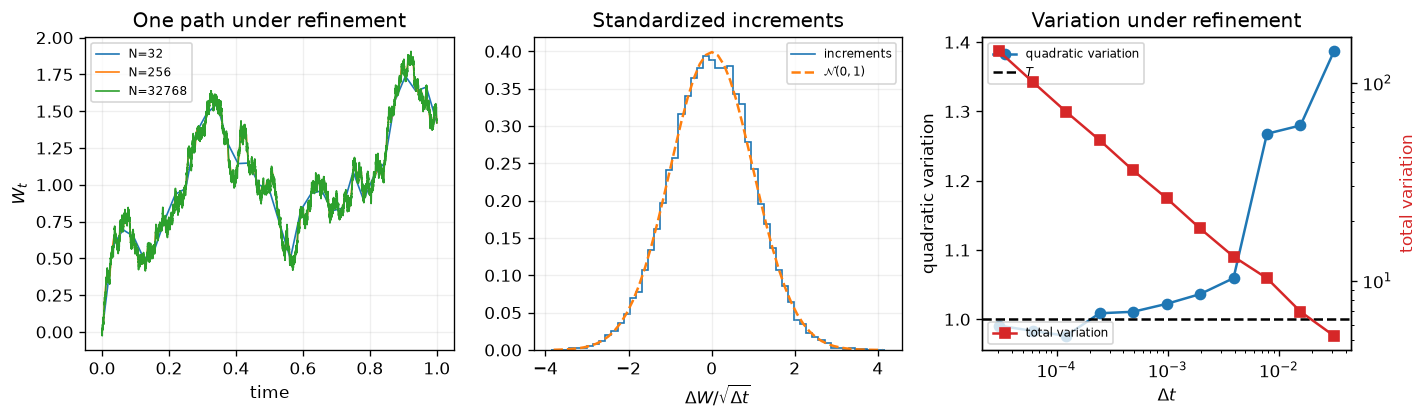

wrote lecture-notes/figures/08_brownian-motion-diffusion/02-wiener-process-quadratic-variation.pdf


In [4]:
figure, axes = plt.subplots(1, 3, figsize=(12.0, 3.6))

for step_count in (32, 256, finest_step_count):
    path = coarse_paths[step_count]
    path_time = np.linspace(0.0, final_time, step_count + 1)
    axes[0].plot(path_time, path, linewidth=1.0, label=f"N={step_count}")
axes[0].set(title="One path under refinement", xlabel="time", ylabel=r"$W_t$")
axes[0].legend(fontsize=7)

standardized_increment = fine_increment / np.sqrt(finest_dt)
histogram, edge = np.histogram(standardized_increment, bins=55, density=True)
center = 0.5 * (edge[:-1] + edge[1:])
normal_density = np.exp(-0.5 * center**2) / np.sqrt(2.0 * np.pi)
axes[1].stairs(histogram, edge, label="increments")
axes[1].plot(center, normal_density, "--", label=r"$\mathcal{N}(0,1)$")
axes[1].set(title="Standardized increments", xlabel=r"$\Delta W/\sqrt{\Delta t}$")
axes[1].legend(fontsize=7)

step_sizes = final_time / step_counts
axes[2].semilogx(step_sizes, quadratic_variation, "o-", label="quadratic variation")
axes[2].axhline(final_time, color="black", linestyle="--", label=r"$T$")
variation_axis = axes[2].twinx()
variation_axis.loglog(step_sizes, total_variation, "s-", color="tab:red", label="total variation")
axes[2].set(title="Variation under refinement", xlabel=r"$\Delta t$", ylabel="quadratic variation")
variation_axis.set_ylabel("total variation", color="tab:red")
axes[2].legend(loc="upper left", fontsize=7)
variation_axis.legend(loc="lower left", fontsize=7)

for axis in axes[:2]:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "02-wiener-process-quadratic-variation.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
